In [52]:
import os
import random 
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

In [30]:
class LenetModel(nn.Module):
    def __init__(self, num_classes):
        super(LenetModel, self).__init__()
        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 6, kernel_size = 5, padding = 'same')
        self.avgPool1 = nn.AvgPool2d(kernel_size = 2)
        self.conv2d = nn.Conv2d(
            in_channels = 6, out_channels = 16, kernel_size = 5
        )
        self.avgPool2 = nn.AvgPool2d(kernel_size = 2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(5 * 5 * 16, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)
    def forward(self, x):
        x = self.conv1(x)
        x = self.avgPool1(x)
        x = F.relu(x)

        x = self.conv2d(x)
        x = self.avgPool2(x)
        x = F.relu(x)
        
        x = self.flatten()
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)
        return x

In [31]:
import torch.utils.data as data 
import torchvision.datasets as datasets
from torchsummary import summary
import matplotlib.pyplot as plt
from PIL import Image 
import torch.optim as optim
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
random_state = 42
random.seed(random_state)
np.random.seed(random_state)
torch.manual_seed(random_state)
torch.mps.manual_seed(random_state)

In [32]:
train_data = datasets.MNIST(
    root = 'data',
    download = True,
    train = True,
)
test_data = datasets.MNIST(
    root = 'data',
    download = True,
    train = False
)

In [33]:
train_data.data.shape

torch.Size([60000, 28, 28])

In [34]:
train_data.classes

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [35]:
train_data.data[0]

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   

In [36]:
train_data.targets[0]

tensor(5)

In [37]:
test_data.data.shape

torch.Size([10000, 28, 28])

25


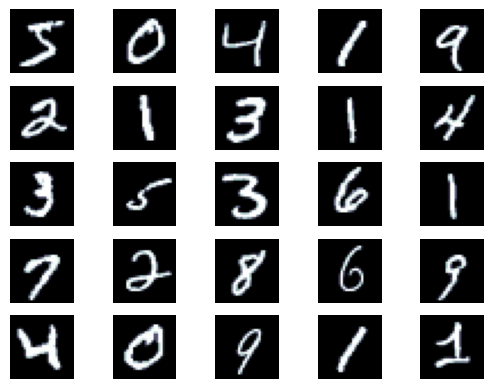

In [38]:
# Plot image
def plot_images(images):
    n_images = len(images)

    rows = int(np.sqrt(n_images))
    cols = int(np.sqrt(n_images))

    fig = plt.figure()
    for i in range(rows * cols):
        ax = fig.add_subplot(rows, cols, i + 1)
        ax.imshow(images[i], cmap = 'bone')
        ax.axis('off')

N_IMAGES = 25
images = [image for image, label in [train_data[i] for i in range(N_IMAGES)]]
print(len(images))
plot_images(images)

<h1>Preprocessing</h1>

In [39]:
# Chia train - valid 9:1
TRAIN_RATIO = 0.9
n_train_examples = int(len(train_data) * TRAIN_RATIO)
n_valid_examples = int(len(train_data) - n_train_examples)

train_data, valid_data = data.random_split(train_data, [n_train_examples, n_valid_examples])
print(len(train_data))
print(len(valid_data))

54000
6000


<span>Preprocessing with transforms</span>
<ul>
  <li>Normalization(mean, std)</li>
  <li>Convert to tensor</li>
</ul>

In [51]:
# compute mean and std
mean = train_data.dataset.data.float().mean() / 255
std = train_data.dataset.data.float().std() / 255
print(mean, std)

tensor(0.1307) tensor(0.3081)


In [53]:
train_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean = [mean], std = [std])
])
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean = [mean], std = [std])
])

In [54]:
train_data.dataset.transform = train_transforms
valid_data.dataset.transform = test_transforms

<h1>Dataloader</h1>

In [57]:
BATCH_SIZE = 256
train_dataloader = data.DataLoader(
    train_data, 
    shuffle = True,
    batch_size = BATCH_SIZE,
)
valid_dataloader = data.DataLoader(
    valid_data,
    batch_size = BATCH_SIZE
)
print(len(train_dataloader))
print(len(valid_dataloader))

211
24


In [58]:
next(iter(train_dataloader))[0].shape

torch.Size([256, 1, 28, 28])

In [60]:
inputs, labels = next(iter(train_dataloader))
print(inputs)
print(labels)

tensor([[[[-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          ...,
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241]]],


        [[[-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          ...,
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241]]],


        [[[-0.4241, -0.4241, -0.4241,  ..., -0.4241, -0.4241, -0.4241],
          [-0.4241, -0.424

In [ ]:
num_classes = len(train_data.dataset.classes)
print(num_classes)